# Formative 3 — Parts 3 & 4: Gradient Descent
**Member 3: Cedric Bigwi Hindura**  ·  Mathematics for Machine Learning (ALU)

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
from src import gradient_descent as gd
from src.plotting import plot_lines
FIG = "figures"
import os; os.makedirs(FIG, exist_ok=True)

---
# Part 3 — Gradient descent: manual calculation (verified in code)

The full handwritten-style derivation is in **`docs/Part3_Manual_Calculations.pdf`**. Here we restate the set-up and *check every manual number with matrix code*.

**Model:** $\hat y = Xm + b$, with $X=\begin{pmatrix}1&3\\4&10\end{pmatrix}$, $y=\begin{pmatrix}5\\6\end{pmatrix}$, $m_0=\begin{pmatrix}-1\\2\end{pmatrix}$, $b_0=\begin{pmatrix}1\\1\end{pmatrix}$.

**Cost:** $J(m,b)=\frac1n(\hat y-y)^\top(\hat y-y)$, $n=2$.

**Chain rule.** Let $u=\hat y-y$, so $J=\frac1n u^\top u$:
$$\frac{\partial J}{\partial u}=\frac{2}{n}u,\qquad \frac{\partial u}{\partial m}=X,\qquad \frac{\partial u}{\partial b}=I
\;\Rightarrow\;
\boxed{\frac{\partial J}{\partial m}=\frac2n X^\top(\hat y-y)},\quad
\boxed{\frac{\partial J}{\partial b}=\frac2n(\hat y-y)}$$

**Update rule:** $m\leftarrow m-\alpha\,\partial J/\partial m$, $\;b\leftarrow b-\alpha\,\partial J/\partial b$ with learning rate $\alpha=0.01$.

**Assumptions we state explicitly** (the brief leaves them open):
* $b=[1,1]^\top$ is treated as a **vector, one bias entry per data point** (so it is a matrix quantity, not a scalar).
* $\alpha=0.01$. Larger values diverge here: the largest eigenvalue of the Hessian is ≈ 127, which requires $\alpha<2/127\approx0.0157$.
* Number of updates = number of group members.

In [2]:
N_MEMBERS = 3        # one gradient-descent update per group member
LR = 0.01
X  = np.array([[1., 3.], [4., 10.]])
y  = np.array([5., 6.])
m0 = np.array([-1., 2.])
b0 = np.array([1., 1.])

**The three hand-calculated updates (one per member) are in `docs/Part3_Manual_Calculations.pdf` and will be demonstrated live during the presentation.** Part 4 below reproduces the same three updates in code so the numbers can be compared line by line.

**Trend.** After each update the cost $J$ falls (61 → 6.50 → 2.50 → 2.16 → …) and the parameters move in the direction of the *negative* gradient, so **yes — the updates reduce the error**. The first step is large because the initial gradient is large (≈45 and ≈113 for $m$); later steps shrink as the gradient flattens. $m_1$ becomes more negative and $m_2$ drops from 2 to about 1.1 — they have not converged yet, but the error is already close to its slowly-decreasing tail.

---
# Part 4 — Gradient descent in code (SciPy)

### 4.1 A function that accepts an equation and returns its derivative (SciPy)
`gd.partial_derivative(f, theta, i)` takes **any equation `f` of a parameter vector** and uses `scipy.differentiate.derivative` to get ∂f/∂θᵢ. `gd.scipy_gradient` stacks these into the gradient. First a sanity check on a function whose derivative we know:

In [3]:
f = lambda t: t[0] ** 3 + 2 * t[0] * t[1] ** 2          # f(x, y) = x^3 + 2xy^2
theta = np.array([2.0, 3.0])
print("SciPy  gradient:", np.round(gd.scipy_gradient(f, theta), 6))
print("Exact  gradient: [3x^2 + 2y^2, 4xy] =", [3 * 2**2 + 2 * 3**2, 4 * 2 * 3])

SciPy  gradient: [30. 24.]
Exact  gradient: [3x^2 + 2y^2, 4xy] = [30, 24]


Now check the SciPy gradient of our MSE cost against the analytic chain-rule formula from Part 3:

In [4]:
g_scipy = gd.scipy_gradient(lambda t: gd.cost_of_theta(t, X, y), gd.pack(m0, b0))
dm_a, db_a = gd.analytic_gradients(X, m0, b0, y)
print("SciPy    [dm, db]:", np.round(g_scipy, 6))
print("Analytic [dm, db]:", np.round(np.concatenate([dm_a, db_a]), 6))
assert np.allclose(g_scipy, np.concatenate([dm_a, db_a]), atol=1e-6)

SciPy    [dm, db]: [ 45. 113.   1.  11.]
Analytic [dm, db]: [ 45. 113.   1.  11.]


### 4.2 Every calculation step visible
The cell below does **not** hide anything inside a helper: predictions → error → cost → SciPy gradients → updates, printed for the first `N_MEMBERS` iterations.

In [5]:
m, b = m0.copy(), b0.copy()
for it in range(1, N_MEMBERS + 1):
    y_hat = X @ m + b                                              # predictions
    error = y_hat - y                                              # residuals
    cost  = error @ error / len(y)                                 # MSE
    grad  = gd.scipy_gradient(lambda t: gd.cost_of_theta(t, X, y), gd.pack(m, b))   # SciPy derivatives
    dm, db = grad[:2], grad[2:]
    m_new, b_new = m - LR * dm, b - LR * db                        # updates
    print(f"iter {it}: y_hat={np.round(y_hat,4)} J={cost:.4f} dm={np.round(dm,4)} db={np.round(db,4)}")
    print(f"        m: {np.round(m,4)} -> {np.round(m_new,4)}    b: {np.round(b,4)} -> {np.round(b_new,4)}")
    m, b = m_new, b_new

iter 1: y_hat=[ 6. 17.] J=61.0000 dm=[ 45. 113.] db=[ 1. 11.]
        m: [-1.  2.] -> [-1.45  0.87]    b: [1. 1.] -> [0.99 0.89]
iter 2: y_hat=[2.15 3.79] J=6.5033 dm=[-11.69 -30.65] db=[-2.85 -2.21]
        m: [-1.45  0.87] -> [-1.3331  1.1765]    b: [0.99 0.89] -> [1.0185 0.9121]
iter 3: y_hat=[3.2149 7.3447] J=2.4974 dm=[3.5937 8.0917] db=[-1.7851  1.3447]
        m: [-1.3331  1.1765] -> [-1.369   1.0956]    b: [1.0185 0.9121] -> [1.0364 0.8987]


### 4.3 Run to (near) convergence and plot

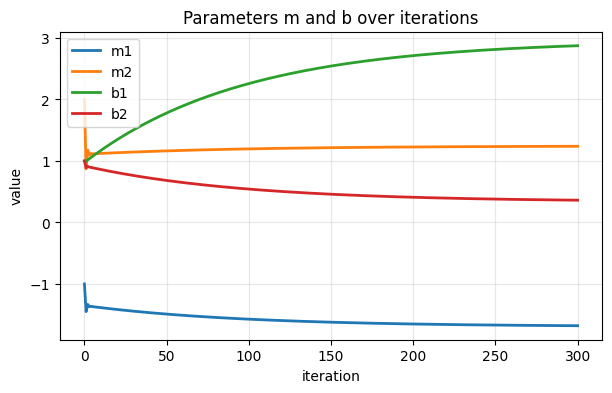

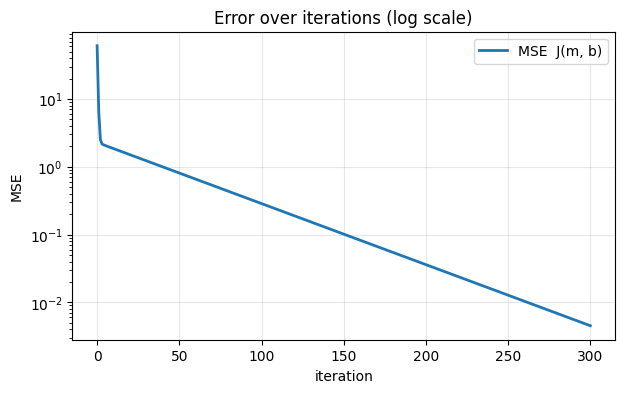

In [6]:
N_ITER = 300
m_fin, b_fin, hist = gd.run_gradient_descent(X, y, m0, b0, LR, N_ITER)
its = [h["iteration"] for h in hist]
M = np.array([h["m"] for h in hist]); B = np.array([h["b"] for h in hist]); J = [h["cost"] for h in hist]

plot_lines(its, {"m1": M[:, 0], "m2": M[:, 1], "b1": B[:, 0], "b2": B[:, 1]},
           "Parameters m and b over iterations", "iteration", "value", path=f"{FIG}/gd_parameters.png"); plt.show()
plot_lines(its, {"MSE  J(m, b)": J}, "Error over iterations (log scale)", "iteration", "MSE", path=f"{FIG}/gd_error.png", logy=True); plt.show()

### 4.4 Predictions with the final m and b

In [7]:
y_pred = gd.predict(X, m_fin, b_fin)
print("final m =", np.round(m_fin, 4), "  final b =", np.round(b_fin, 4))
pd.DataFrame({"x": [tuple(r) for r in X], "y (true)": y, "y_hat (final)": y_pred, "error": y_pred - y})

final m = [-1.6794  1.2382]   final b = [2.8734 0.3618]


,x,y (true),y_hat (final),error
0,"(1.0, 3.0)",5.0,4.908739,-0.091261
1,"(4.0, 10.0)",6.0,6.026756,0.026756


In [8]:
print(f"Final MSE after {N_ITER} iterations: {J[-1]:.6f}  (started at {J[0]:.1f})")

Final MSE after 300 iterations: 0.004522  (started at 61.0)


---
## Reproducibility
`pip install -r requirements.txt`, place `GaltonFamilies.csv` and `IMDB Dataset.csv` in `data/`, then *Run All*. All modules live in `src/` (one responsibility per file, no duplicated logic).